In [ ]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import clear_output

## 1. Q-learning in the wild (3 pts)

Use your Q-learning agent with Gymnasium’s `Taxi-v4` environment. Complete the agent methods and the training update in `play_and_train`.


Episode 0, mean reward (last 100): -650.00, epsilon: 0.2475
Episode 100, mean reward (last 100): -273.07, epsilon: 0.0906
Episode 200, mean reward (last 100): -70.05, epsilon: 0.0332
Episode 300, mean reward (last 100): -10.23, epsilon: 0.0121
Episode 400, mean reward (last 100): 2.29, epsilon: 0.0044
Episode 500, mean reward (last 100): 6.48, epsilon: 0.0016
Episode 600, mean reward (last 100): 6.89, epsilon: 0.0006
Episode 700, mean reward (last 100): 7.61, epsilon: 0.0002
Episode 800, mean reward (last 100): 7.83, epsilon: 0.0001
Episode 900, mean reward (last 100): 7.66, epsilon: 0.0000


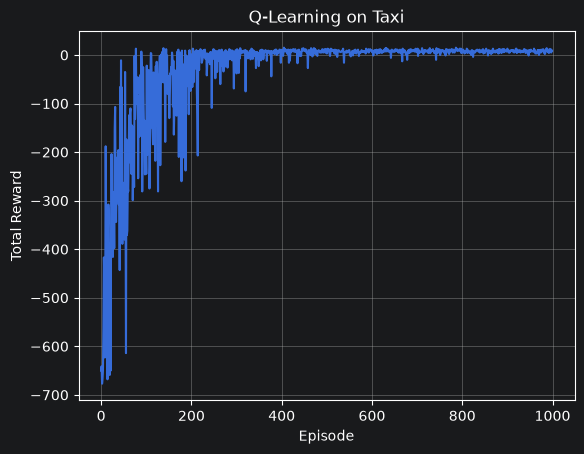

In [1]:
import random, math
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt
from collections import defaultdict


class QLearningAgent():#создаем агента

    def __init__(self, alpha, epsilon, discount, getLegalActions):
        "We initialize agent and Q-values here."
        self.getLegalActions = getLegalActions
        self._qValues = defaultdict(lambda: defaultdict(lambda: 0))
        self.alpha = alpha
        self.epsilon = epsilon
        self.discount = discount

    def getQValue(self, state, action):
        if not (state in self._qValues) or not (action in self._qValues[state]):
            return 0.0
        return self._qValues[state][action]

    def setQValue(self, state, action, value):
        """
        Sets the Qvalue for [state,action] to the given value
        """
        self._qValues[state][action] = value

    #---------------------#start of your code#---------------------#
# методы Q-LEARNING включают оценку ситуации, выбор следующего хода и обновление знаний агента после каждого шага
    def getValue(self, state):#оцениваем ситуацию
        """
        Returns max_action Q(state,action)
        where the max is over legal actions.
        """
        possibleActions = self.getLegalActions(state)
        if len(possibleActions) == 0:
            return 0.0

        return max(self.getQValue(state, action) for action in possibleActions)

    def getPolicy(self, state):#жадная стратегия
        """
        Compute the best action to take in a state.
        """
        possibleActions = self.getLegalActions(state)
        if len(possibleActions) == 0:
            return None

        best_value = self.getValue(state)
        best_actions = [
            action for action in possibleActions
            if self.getQValue(state, action) == best_value
        ]
        return random.choice(best_actions)

    def getAction(self, state):
        """
        Compute the action to take in the current state, including exploration.
        """
        possibleActions = self.getLegalActions(state)
        if len(possibleActions) == 0:
            return None

        if random.random() < self.epsilon:
            action = random.choice(possibleActions)
        else:
            action = self.getPolicy(state)

        return action

    def update(self, state, action, nextState, reward):#обучение на опыте
        """
        You should do your Q-Value update here
        """
        gamma = self.discount
        learning_rate = self.alpha

        reference_qvalue = reward + gamma * self.getValue(nextState)
        updated_qvalue = (1 - learning_rate) * self.getQValue(state, action) + learning_rate * reference_qvalue
        self.setQValue(state, action, updated_qvalue)


def play_and_train(env, agent, t_max=10**4):#игровой эпизод
    """
    Runs one episode, updating agent's Q-values at each step.
    Returns total reward for the episode.
    """
    total_reward = 0.0
    s, _ = env.reset()

    for t in range(t_max):
        a = agent.getAction(s)
        next_s, r, terminated, truncated, _ = env.step(a)
        done = terminated or truncated

        agent.update(s, a, next_s, r)

        s = next_s
        total_reward += r
        if done:
            break

    return total_reward

#создаем и обучаем
try:
    env = gym.make("Taxi-v4")
except gym.error.NameNotFound:
    env = gym.make("Taxi-v3")

n_actions = env.action_space.n

agent = QLearningAgent(
    alpha=0.5,
    epsilon=0.25,
    discount=0.99,
    getLegalActions=lambda s: range(n_actions)
)

rewards = []
for i in range(1000):
    rewards.append(play_and_train(env, agent))
    agent.epsilon *= 0.99  # Постепенно уменьшаем вероятность случайных действий

    if i % 100 == 0:
        print(f"Episode {i}, mean reward (last 100): {np.mean(rewards[-100:]):.2f}, epsilon: {agent.epsilon:.4f}")

# График обучения
plt.plot(rewards)
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Q-Learning on Taxi")
plt.grid(True)
plt.show()

Достигните положительной награды, постройте график

In [ ]:
from IPython.display import clear_output


1.260215853156675e-09


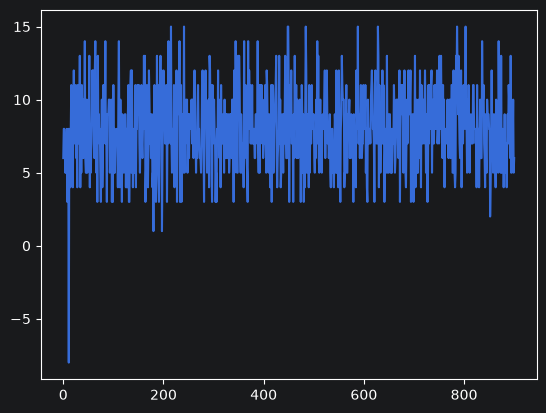

In [2]:
from IPython.display import clear_output
rewards = []
for i in range(1000):
    rewards.append(play_and_train(env, agent))
    agent.epsilon *= 0.99  # уменьшайте со временем, если не уменьшать, то агент не будет обучаться и будет совершать прежние ошибки
    if i % 100 == 0:
        clear_output(True)
        print(agent.epsilon)
        plt.plot(rewards)
        plt.show()

## 3. Continuous state space (2 pt)

Чтобы использовать табличный q-learning на continuous состояниях, надо как-то их обрабатывать и бинаризовать. Придумайте способ разбивки на дискретные состояния.

In [2]:
# Keep the original 200-step limit for the 195-point training target.
env = gym.make("CartPole-v1", max_episode_steps=200)
n_actions = env.action_space.n
state, _ = env.reset()
print(f"first state: {state}")

first state: [ 0.01801716 -0.00303719  0.01786379 -0.00999303]


### Play a few games

Постройте распределения различных частей состояния игры. Сыграйте несколько игр и запишите все состояния.

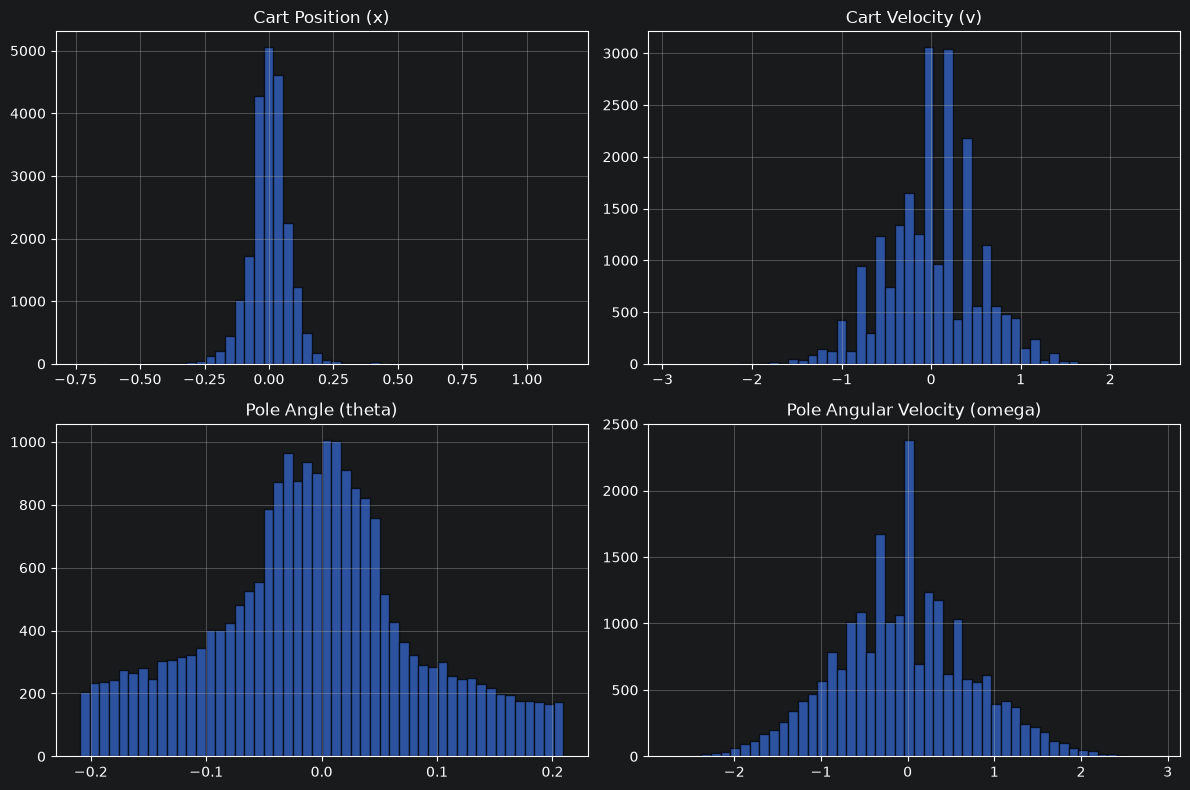

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym

env = gym.make("CartPole-v1", max_episode_steps=200)
n_actions = env.action_space.n

# Играем 1000 эпизодов со случайными действиями и сохраняем все состояния
states = []
for _ in range(1000):
    s, _ = env.reset()
    done = False
    while not done:
        states.append(s)
        a = env.action_space.sample()
        s, r, terminated, truncated, _ = env.step(a)
        done = terminated or truncated

states = np.array(states)

# Строим гистограммы для каждой из 4 компонент состояния
feature_names = ['Cart Position (x)', 'Cart Velocity (v)', 'Pole Angle (theta)', 'Pole Angular Velocity (omega)']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, ax in enumerate(axes.flat):
    ax.hist(states[:, i], bins=50, edgecolor='black', alpha=0.7)
    ax.set_title(feature_names[i])
    ax.grid(True)

plt.tight_layout()
plt.show()

## Binarize environment

In [6]:
import numpy as np
import gymnasium as gym
from gymnasium import ObservationWrapper


class Binarizer(ObservationWrapper):
    def __init__(self, env, n_bins=(6, 6, 12, 12)):
        super().__init__(env)
        # Рабочие диапазоны для каждой из 4 компонент состояния CartPole
        self.bins = [
            np.linspace(-2.4, 2.4, n_bins[0] - 1),   # Позиция
            np.linspace(-3.0, 3.0, n_bins[1] - 1),   # Скорость
            np.linspace(-0.25, 0.25, n_bins[2] - 1), # Угол шеста
            np.linspace(-3.5, 3.5, n_bins[3] - 1),   # Угловая скорость
        ]
        # Задаём дискретное пространство наблюдений в соответствии с числом корзин
        self.observation_space = gym.spaces.MultiDiscrete(n_bins)

    def to_bin(self, value, bins):
        return int(np.digitize(value, bins))

    def observation(self, state):
        return tuple(
            self.to_bin(state[i], self.bins[i])
            for i in range(len(state))
        )


env = Binarizer(gym.make("CartPole-v1", max_episode_steps=200))

## Learn

0.11891344262766605
196.3
Win!


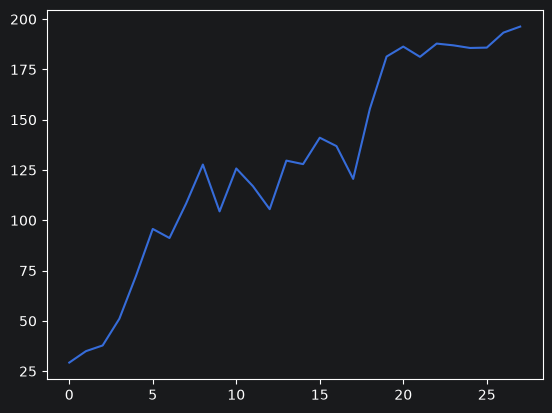

In [7]:
agent = QLearningAgent(
    alpha=0.1,#низкая скорость
    epsilon=0.5,#толкаем тележку в 50% случаев случайно чтобы исследовать углы
    discount=0.99,#за каждый шаг дается награда+1
    getLegalActions=lambda s: range(n_actions)
)

rewards = []
rewBuf = []
ma = -1000000000000

for i in range(10000):
    for _ in range(100):
        rewards.append(play_and_train(env, agent))
    agent.epsilon *= 0.95
    rewBuf.append(np.mean(rewards[-100:]))
    clear_output(True)
    print(agent.epsilon)
    print(rewBuf[-1])
    plt.plot(rewBuf)
    if rewBuf[-1] > 195:
        print("Win!")
        break
    plt.show()

## 4. Experience replay (5 pts)

In [8]:
import random
import numpy as np


class ReplayBuffer(object):#позволяет не забывать партию сразу после завершения, а использовать редкий опыт(например момент падения шеста),миксовать шаги из разных партий
    def __init__(self, size):
        self._storage = []
        self._maxsize = size
        self._replaceId = 0

    def __len__(self):
        return len(self._storage)

    def add(self, obs_t, action, reward, obs_tp1, done):#записываем новый опыт в память
        data = (obs_t, action, reward, obs_tp1, done)
        if len(self._storage) == self._maxsize:
            self._storage[self._replaceId] = data
            self._replaceId = (self._replaceId + 1) % self._maxsize
        else:
            self._storage.append(data)

    def sample(self, batch_size):#случайная выборка батча обучения
        batch = [random.choice(self._storage) for _ in range(batch_size)]
        obs_batch, act_batch, rew_batch, next_obs_batch, done_mask = zip(*batch)

        states = np.array(obs_batch)
        actions = np.array(act_batch)
        rewards = np.array(rew_batch)
        next_states = np.array(next_obs_batch)
        is_done = np.array(done_mask, dtype=np.float32)

        return states, actions, rewards, next_states, is_done



Some tests to make sure your buffer works right

In [9]:
import numpy as np
replay = ReplayBuffer(2)
obj1 = tuple(range(5))
obj2 = tuple(range(5, 10))
replay.add(*obj1)
assert replay.sample(1)==obj1, "If there's just one object in buffer, it must be retrieved by buf.sample(1)"
replay.add(*obj2)
assert len(replay._storage)==2, "Please make sure __len__ methods works as intended."
replay.add(*obj2)
assert len(replay._storage)==2, "When buffer is at max capacity, replace objects instead of adding new ones."
assert tuple(np.unique(a) for a in replay.sample(100))==obj2
replay.add(*obj1)
assert max(len(np.unique(a)) for a in replay.sample(100))==2
replay.add(*obj1)
assert tuple(np.unique(a) for a in replay.sample(100))==obj1
print ("Success!")

Success!


Now let's use this buffer to improve training:

In [ ]:
env = Binarizer(gym.make("CartPole-v1", max_episode_steps=200))
n_actions = env.action_space.n

In [ ]:
agent = QLearningAgent(alpha=,epsilon=,discount=,
                       getLegalActions = lambda s: range(n_actions))
replay = ReplayBuffer(10000)

In [10]:
env = Binarizer(gym.make("CartPole-v1", max_episode_steps=200))
n_actions = env.action_space.n
agent = QLearningAgent(
    alpha=0.1,
    epsilon=0.5,
    discount=0.99,
    getLegalActions=lambda s: range(n_actions)
)
replay = ReplayBuffer(10000)


def play_and_train(env, agent, t_max=10**4, batch_size=10):
    """Run one episode, train the agent from replay, and return total reward."""
    total_reward = 0.0
    state, _ = env.reset()
    for _ in range(t_max):
        action = agent.getAction(state)
        next_state, reward, terminated, truncated, _ = env.step(action)

        # Сохраняем переход в буфер (передаём именно terminated в поле done)
        replay.add(state, action, reward, next_state, terminated)

        # Обучаем агента на текущем переходе
        agent.update(state, action, next_state, reward)

        state = next_state
        total_reward += reward
        if terminated or truncated:
            break

    # Обучаем агента на случайном батче переходов из буфера
    states, actions, rewards, next_states, is_done = replay.sample(batch_size)
    for s, a, r, next_s, done in zip(states, actions, rewards, next_states, is_done):
        # np.array превращает кортеж в 1D-массив, поэтому возвращаем состояния в tuple
        s_tuple = tuple(s)
        next_s_tuple = tuple(next_s)
        # Если эпизод завершился терминально (done == 1.0), будущая награда равна 0
        if done:
            target = r
            updated_q = (1 - agent.alpha) * agent.getQValue(s_tuple, int(a)) + agent.alpha * target
            agent.setQValue(s_tuple, int(a), updated_q)
        else:
            agent.update(s_tuple, int(a), next_s_tuple, r)

    return total_reward

Train with experience replay

0.09843720217036128
198.0
Win!


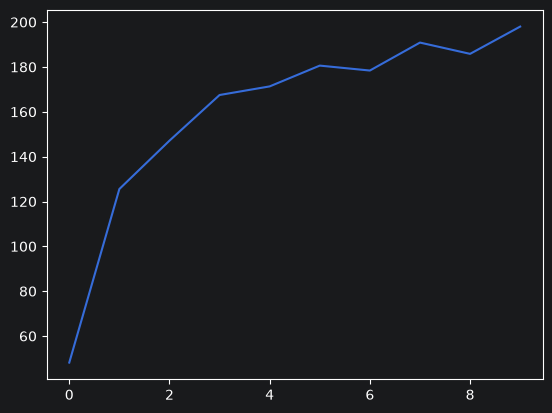

In [11]:
rewards = []
rewBuf = []
ma = -1000000000000

for i in range(10000):
    for _ in range(100):
        rewards.append(play_and_train(env, agent, batch_size=1000))
    agent.epsilon *= 0.85
    rewBuf.append(np.mean(rewards[-100:]))
    clear_output(True)
    print(agent.epsilon)
    print(rewBuf[-1])
    plt.plot(rewBuf)
    if rewBuf[-1] > 195:
        print("Win!")
        break
    plt.show()
